In [1]:
import numpy as np
import pandas as pd


In [2]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import LabelEncoder

In [3]:
data=pd.read_csv("mental_health.csv")
data

,text,status
0,i don't understand whats wrong with me. i don'...,Anxiety
1,usually when i have anxiety just chatting with...,Anxiety
2,"well, i've had anxiety and panic syndrome for ...",Anxiety
3,"for the most minimal of things, like standing ...",Anxiety
4,i stay away from family and live with my roomm...,Anxiety
...,...,...
987,Someone jumped off my building todayI wonder w...,Suicidal
988,helpp??? took 2800mg ibuprofen &amp; 1800mg as...,Suicidal
989,I flunked all my exams am gonna suicideAm goin...,Suicidal
990,I've Got A Serious ProblemI am considering tak...,Suicidal


In [4]:
text = data['text']
y = data['status']

In [5]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(text)
X

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 79338 stored elements and shape (992, 8614)>

In [6]:
model = MultinomialNB()
model.fit(X, y)


MultinomialNB()

In [13]:
text = input(("Enter message: "))
x = vectorizer.transform([text])
pred = model.predict(x)
print(pred)

Enter message: My heart races when I think about exams, and I keep imagining the worst.
['Anxiety']


In [14]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score


In [19]:
y_pred = model.predict(X)

accuracy = accuracy_score(y, y_pred)
accuracy

0.8800403225806451

In [22]:
precision = precision_score(y, y_pred, average='weighted')
precision

0.891504366386881

In [24]:
recall=recall_score(y,y_pred,average='weighted')
recall

0.8800403225806451

In [25]:
f1=f1_score(y,y_pred,average='weighted')
f1

0.878197465811421

In [28]:
cm=confusion_matrix(y,y_pred)
cm

array([[234,   6,   0,   8],
       [  5, 219,   0,  24],
       [ 20,  20, 178,  30],
       [  0,   3,   3, 242]])

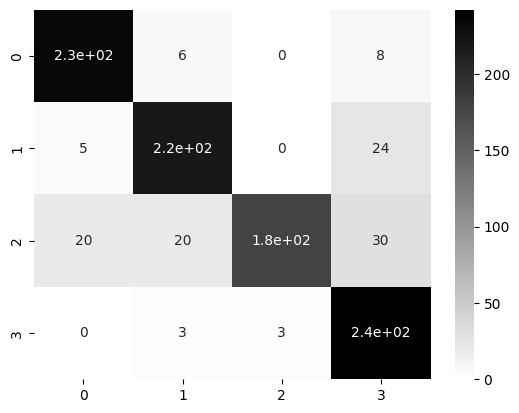

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(cm,annot=True,cmap="binary")
plt.show()